## 1. Data Loading & Setup

In [1]:
!pip install -q kagglehub[pandas-datasets]

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import kagglehub
from kagglehub import KaggleDatasetAdapter

In [3]:
events = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "azizkasimov/wind-turbine-scada-data-for-early-fault-detection",
    "Wind Farm A/comma_event_info.csv",
)

cols_to_keep = [
    "id", "asset_id", "time_stamp", "train_test", "status_type_id",
    "wind_speed_3_avg", "sensor_0_avg", "sensor_1_avg",
    "sensor_11_avg", "sensor_43_avg", "sensor_50"
]

all_dfs = []
for eid in events["event_id"]:
    temp = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        "azizkasimov/wind-turbine-scada-data-for-early-fault-detection",
        f"Wind Farm A/datasets/comma_{eid}.csv",
    )
    temp = temp[cols_to_keep].copy()
    temp["event_id"] = eid
    all_dfs.append(temp)

df = pd.concat(all_dfs, ignore_index=True)
df = df[[
    "id", "event_id", "asset_id", "time_stamp", "train_test", "status_type_id",
    "wind_speed_3_avg", "sensor_0_avg", "sensor_1_avg",
    "sensor_11_avg", "sensor_43_avg", "sensor_50"
]]
df.shape

/tmp/ipykernel_1743/3557076740.py:1: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  events = kagglehub.load_dataset(


Using Colab cache for faster access to the 'wind-turbine-scada-data-for-early-fault-detection' dataset.


/tmp/ipykernel_1743/3557076740.py:15: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


Using Colab cache for faster access to the 'wind-turbine-scada-data-for-early-fault-detection' dataset.


/tmp/ipykernel_1743/3557076740.py:15: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


Using Colab cache for faster access to the 'wind-turbine-scada-data-for-early-fault-detection' dataset.


... (31 outputs left out)

Using Colab cache for faster access to the 'wind-turbine-scada-data-for-early-fault-detection' dataset.


/tmp/ipykernel_1743/3557076740.py:15: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


Using Colab cache for faster access to the 'wind-turbine-scada-data-for-early-fault-detection' dataset.


(1196747, 12)

In [4]:
events["event_description"] = events["event_description"].fillna("Normal")

df = df.rename(columns={
    "wind_speed_3_avg": "wind_speed",
    "sensor_0_avg": "ambient_temp",
    "sensor_1_avg": "wind_direction",
    "sensor_11_avg": "gearbox_temp",
    "sensor_43_avg": "nacelle_temp",
    "sensor_50": "power_output"
})

df["time_stamp"] = pd.to_datetime(df["time_stamp"])
events["event_start"] = pd.to_datetime(events["event_start"])
events["event_end"] = pd.to_datetime(events["event_end"])

for col in ["wind_speed", "power_output"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    df[col] = df[col].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

status_types = pd.DataFrame({
    "status_type_id": [0, 1, 2, 3, 4, 5],
    "status_name": ["Normal", "Derated", "Idling", "Service", "Downtime", "Other"],
    "considered_normal": [1, 0, 1, 0, 0, 0]
})

data = df.merge(events[["event_id", "event_label", "event_description"]], on="event_id", how="left")
data = data.merge(status_types[["status_type_id", "status_name"]], on="status_type_id", how="left")
data["month"] = data["time_stamp"].dt.to_period("M").astype(str)
data.head()

,id,event_id,asset_id,time_stamp,train_test,status_type_id,wind_speed,ambient_temp,wind_direction,gearbox_temp,nacelle_temp,power_output,event_label,event_description,status_name,month
0,0,68,11,2014-07-29 13:20:00,train,5,3.9,31.0,152.0,40.0,38.0,-1185.0,anomaly,Transformer failure,Other,2014-07
1,1,68,11,2014-07-29 13:30:00,train,5,6.0,31.0,86.1,40.0,38.0,-1050.0,anomaly,Transformer failure,Other,2014-07
2,2,68,11,2014-07-29 13:40:00,train,5,6.3,31.0,115.2,39.0,38.0,-1043.0,anomaly,Transformer failure,Other,2014-07
3,3,68,11,2014-07-29 13:50:00,train,0,6.0,32.0,129.3,43.0,37.0,40124.0,anomaly,Transformer failure,Normal,2014-07
4,4,68,11,2014-07-29 14:00:00,train,0,7.1,32.0,137.7,49.0,36.0,99360.0,anomaly,Transformer failure,Normal,2014-07


## 2. Exploratory Data Analysis (EDA)

In [5]:
num_cols = ["wind_speed", "ambient_temp", "wind_direction", "gearbox_temp", "nacelle_temp", "power_output"]
print(data[num_cols].describe().round(2))
print()
print(data["event_label"].value_counts())
print()
print(data["status_name"].value_counts())

       wind_speed  ambient_temp  wind_direction  gearbox_temp  nacelle_temp  \
count  1196747.00    1196747.00      1196747.00    1196747.00    1196747.00   
mean         6.18         19.95          170.85         51.62         30.11   
std          3.66          5.56           92.59         10.24          5.40   
min          0.40          4.00            0.00         15.00         15.00   
25%          3.20         16.00           97.90         44.00         26.00   
50%          5.50         19.00          129.40         53.00         30.00   
75%          8.50         24.00          260.10         60.00         34.00   
max         16.45         41.00          359.00         72.00         51.00   

       power_output  
count    1196747.00  
mean       93045.41  
std       113567.95  
min        -5367.00  
25%         -561.00  
50%        38827.00  
75%       161188.00  
max       371256.00  

event_label
normal     601394
anomaly    595353
Name: count, dtype: int64

status_name
No

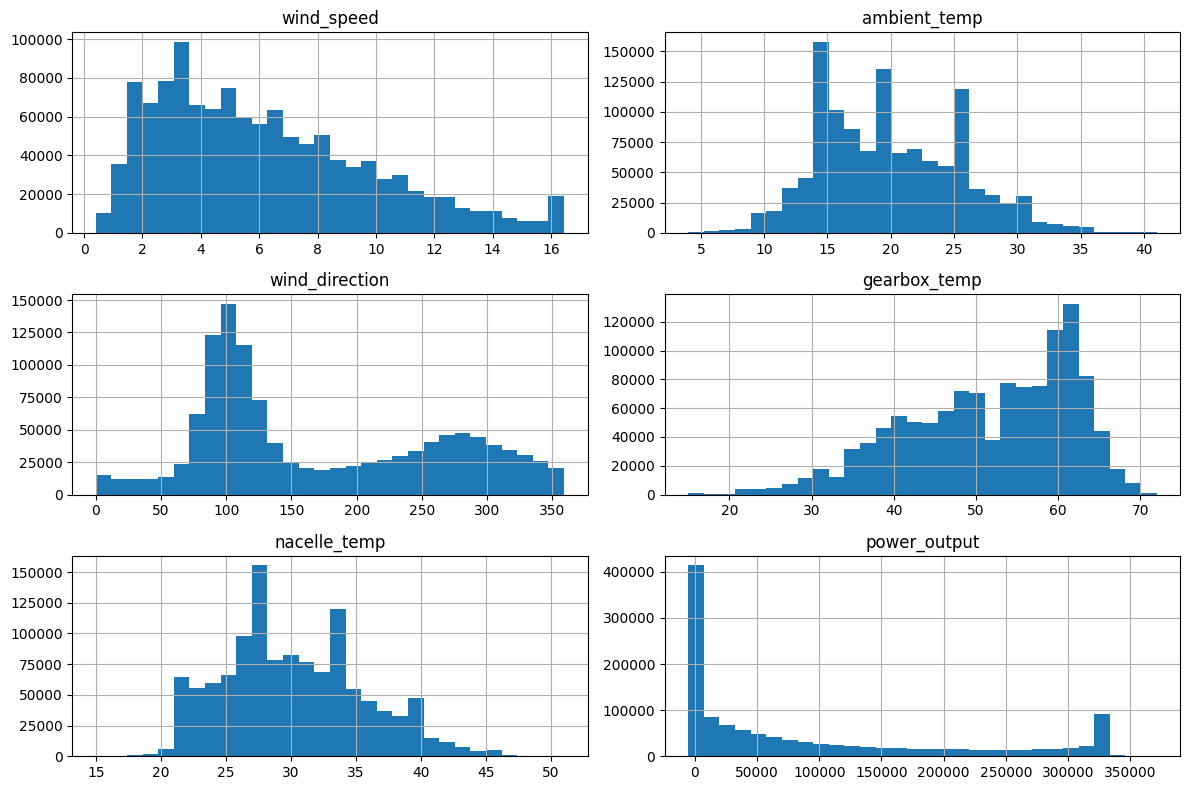

In [6]:
data[num_cols].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

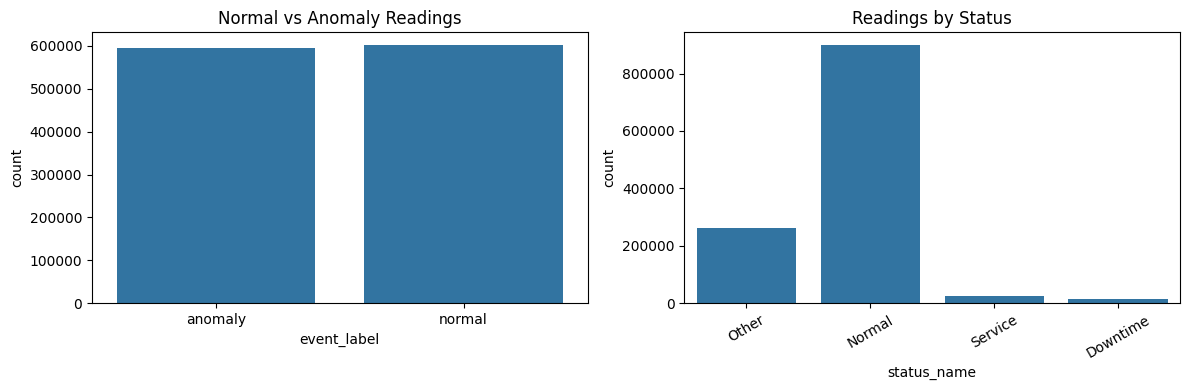

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=data, x="event_label", ax=axes[0])
axes[0].set_title("Normal vs Anomaly Readings")
sns.countplot(data=data, x="status_name", ax=axes[1])
axes[1].set_title("Readings by Status")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

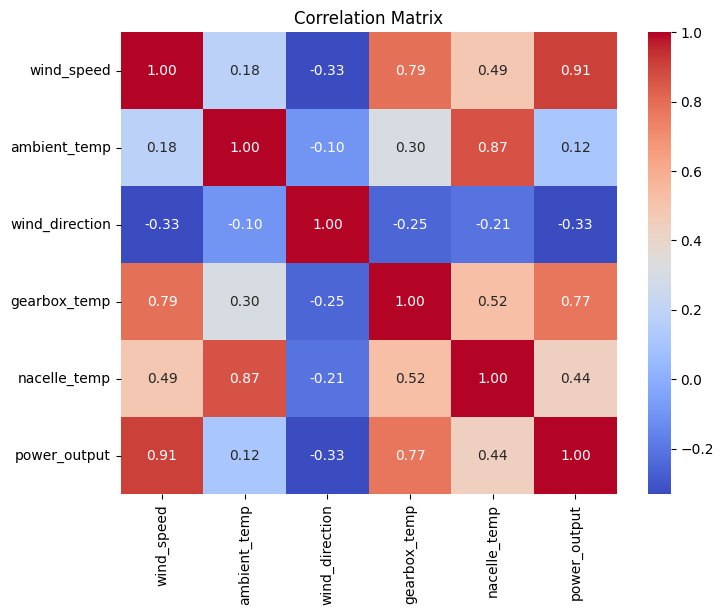

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(data[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

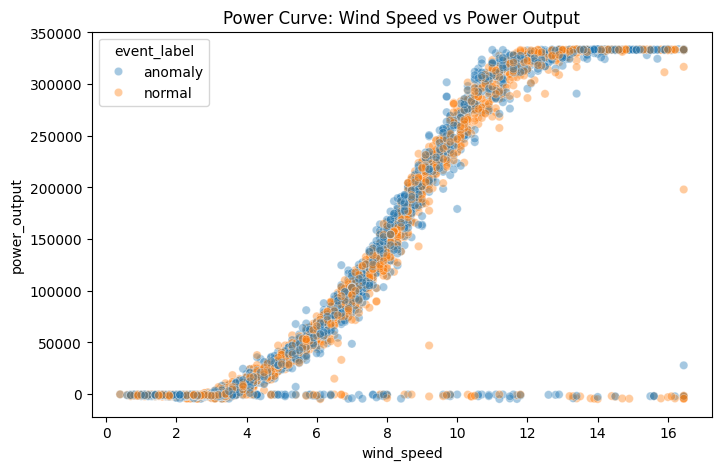

In [9]:
sample = data.sample(5000, random_state=42)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="wind_speed", y="power_output", hue="event_label", alpha=0.4)
plt.title("Power Curve: Wind Speed vs Power Output")
plt.show()

In [10]:
by_event = data.groupby("event_label")[["wind_speed", "power_output", "gearbox_temp", "nacelle_temp", "ambient_temp"]].mean().round(2)
print(by_event)
print()
by_status = data.groupby("status_name")[["wind_speed", "power_output", "gearbox_temp"]].agg(["count", "mean"]).round(2)
print(by_status)

             wind_speed  power_output  gearbox_temp  nacelle_temp  \
event_label                                                         
anomaly            6.19      93437.68         51.62         30.25   
normal             6.17      92657.07         51.63         29.97   

             ambient_temp  
event_label                
anomaly             20.03  
normal              19.88  

            wind_speed       power_output            gearbox_temp       
                 count  mean        count       mean        count   mean
status_name                                                             
Downtime         13999  5.39        13999   69756.44        13999  52.75
Normal          898672  6.90       898672  117666.72       898672  54.42
Other           260387  3.62       260387    9554.20       260387  42.19
Service          23689  7.50        23689   90494.13        23689  48.84


In [11]:
by_asset = data.groupby("asset_id")[["wind_speed", "power_output", "gearbox_temp"]].agg(["count", "mean", "max"]).round(2)
print(by_asset)
print()
by_fault = data.groupby("event_description")[["wind_speed", "power_output", "gearbox_temp"]].mean().round(2)
print(by_fault)

         wind_speed              power_output                      \
              count  mean    max        count      mean       max   
asset_id                                                            
0            272477  6.40  16.45       272477  96742.05  334355.0   
10           274213  6.04  16.45       274213  86870.59  334458.0   
11           217950  6.16  16.45       217950  90643.15  371256.0   
13           216543  6.09  16.45       216543  95247.27  334277.0   
21           215564  6.19  16.45       215564  96444.58  334398.0   

         gearbox_temp               
                count   mean   max  
asset_id                            
0              272477  51.39  68.0  
10             274213  49.93  72.0  
11             217950  50.85  68.0  
13             216543  55.00  72.0  
21             215564  51.46  69.0  

                           wind_speed  power_output  gearbox_temp
event_description                                                
Gearbox failure   

## 3. Data Visualization

In [12]:
total_readings = len(data)
total_turbines = data["asset_id"].nunique()
normal_pct = (data["status_name"] == "Normal").mean() * 100
avg_wind = data["wind_speed"].mean()
avg_power = data["power_output"].mean()
avg_gearbox = data["gearbox_temp"].mean()
anomaly_events = (events["event_label"] == "anomaly").sum()

print("Total Readings:", total_readings)
print("Total Turbines:", total_turbines)
print("Normal Operation (%):", round(normal_pct, 2))
print("Average Wind Speed:", round(avg_wind, 2))
print("Average Power Output:", round(avg_power, 2))
print("Average Gearbox Temp:", round(avg_gearbox, 2))
print("Anomaly Events:", anomaly_events)

Total Readings: 1196747
Total Turbines: 5
Normal Operation (%): 75.09
Average Wind Speed: 6.18
Average Power Output: 93045.41
Average Gearbox Temp: 51.62
Anomaly Events: 11


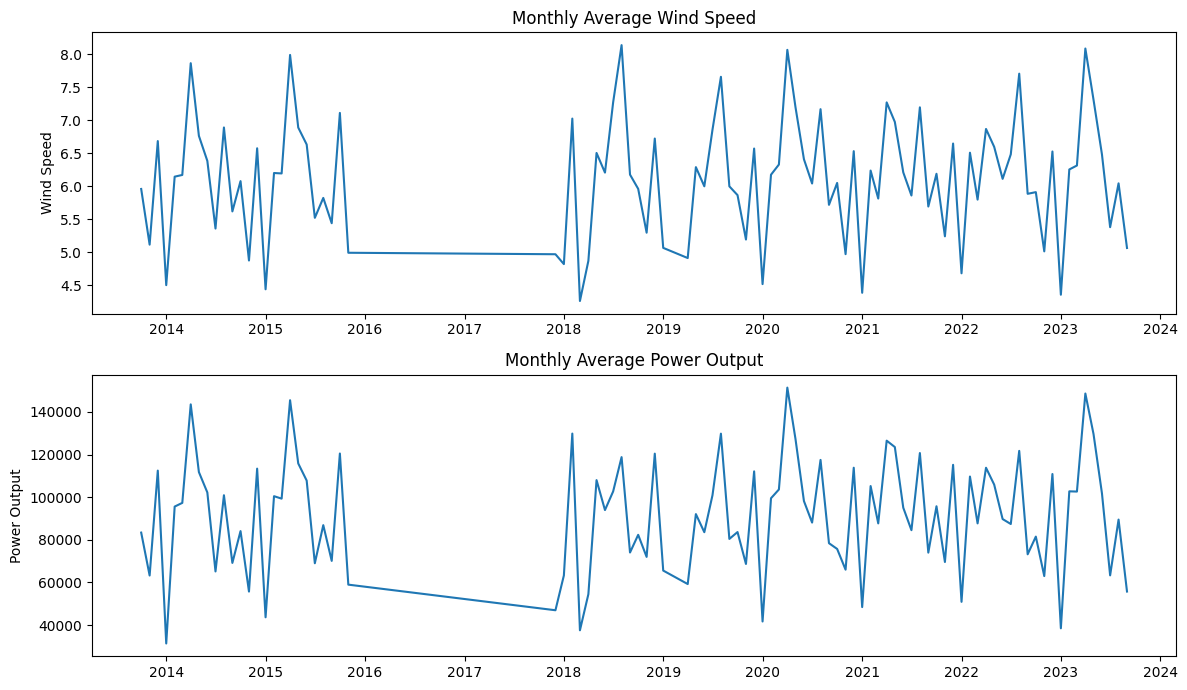

In [13]:
monthly = data.groupby("month")[["wind_speed", "power_output"]].mean().reset_index()
monthly["month"] = pd.to_datetime(monthly["month"])

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(monthly["month"], monthly["wind_speed"])
axes[0].set_title("Monthly Average Wind Speed")
axes[0].set_ylabel("Wind Speed")
axes[1].plot(monthly["month"], monthly["power_output"])
axes[1].set_title("Monthly Average Power Output")
axes[1].set_ylabel("Power Output")
plt.tight_layout()
plt.show()

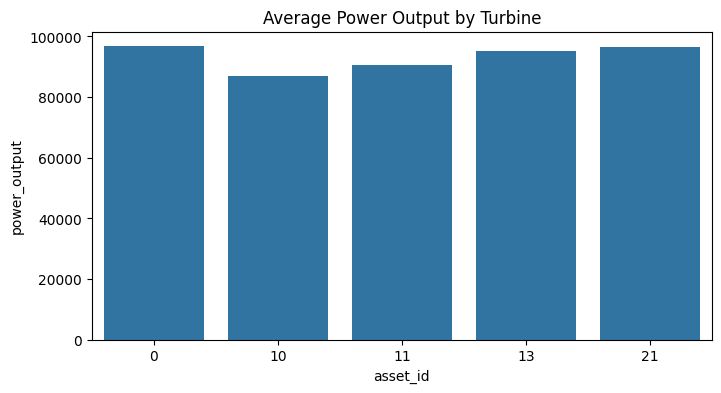

In [14]:
asset_power = data.groupby("asset_id")["power_output"].mean().reset_index()
plt.figure(figsize=(8, 4))
sns.barplot(data=asset_power, x="asset_id", y="power_output")
plt.title("Average Power Output by Turbine")
plt.show()

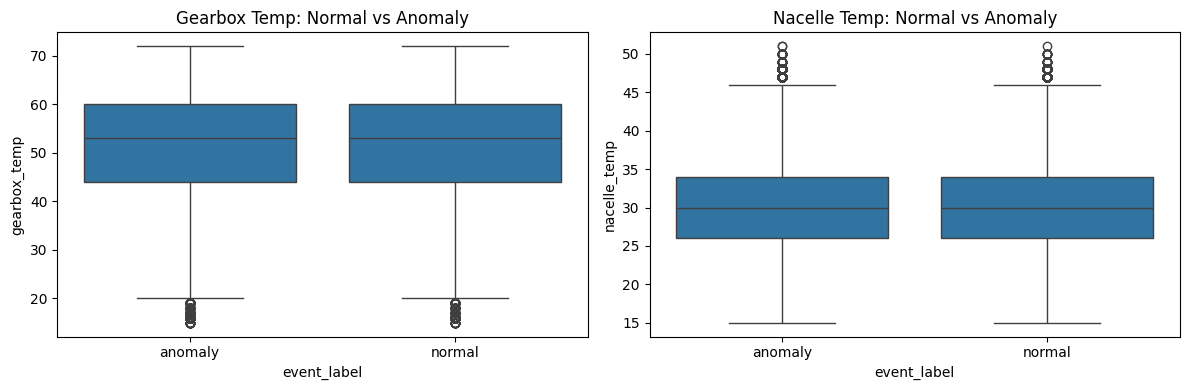

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=data, x="event_label", y="gearbox_temp", ax=axes[0])
axes[0].set_title("Gearbox Temp: Normal vs Anomaly")
sns.boxplot(data=data, x="event_label", y="nacelle_temp", ax=axes[1])
axes[1].set_title("Nacelle Temp: Normal vs Anomaly")
plt.tight_layout()
plt.show()

In [16]:
fig = px.scatter(
    sample,
    x="wind_speed",
    y="power_output",
    color="event_label",
    hover_data=["asset_id", "gearbox_temp", "nacelle_temp", "status_name"],
    title="Interactive Power Curve"
)
fig.show()